# 056 — lightgbm afinacao

LightGBM 041: mantém 126 árvores, 31 folhas e learning rate 0,03. Testa min_child_samples, L1/L2 e pesos suaves por classe, calculados só no treino de cada fold.

**Estado: executado pelo runner; resultados locais guardados.** A seleção usa três folds dentro de 8.769 linhas. A validação fixa de 2.193 linhas é desenvolvimento, não teste independente. Nenhum modelo usa AGE_RANGE ou identificadores nas entradas.

056 resultado completo reutilizado após verificar contexto.
Protocolo: 3 folds dentro de 8769 linhas; 2193 apenas para desenvolvimento. Sem early stopping: número de árvores histórico fixo.
Selecionado: {'label': 'pesos_suaves', 'kind': 'lgb', 'params': {'num_leaves': 31, 'learning_rate': 0.03, 'n_estimators': 126, 'min_child_samples': 20, 'reg_alpha': 0.0, 'reg_lambda': 0.0}, 'weighting': 'inverse_sqrt'}
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração da corrida original (s), incluindo preparação e avaliação: 131.85296354199818
Diferenças emparelhadas CV: {'differences': [0.001827039829427668, -0.009821636004923862, 0.010805566554095258], 'mean': 0.0009369901261996882, 'std': 0.010342364947552538}
Por escalão: controlo
Por escalão: selecionado
CSV: {'path': 'submissions/submission_056_lightgbm_afinacao.csv', 'duplicate_of': [], 'differences': {'submission_001_regressao_logist

,configuração,Macro F1 CV,DP,folds
0,controlo_041,0.445954,0.004962,"[0.4494260991644261, 0.44027010371896325, 0.44..."
1,folhas_min_50,0.442851,0.008394,"[0.4387079268356533, 0.4373347117042967, 0.452..."
2,folhas_min_100,0.442307,0.011896,"[0.43634103246747297, 0.4345745313541802, 0.45..."
3,regularizacao_moderada,0.442218,0.005636,"[0.43595354478793463, 0.4438261585900787, 0.44..."
4,regularizacao_forte,0.431869,0.001908,"[0.4336223173280539, 0.4298379426040354, 0.432..."
5,pesos_suaves,0.446891,0.014753,"[0.4512531389938538, 0.4304484677140394, 0.458..."
6,combinado,0.441126,0.001299,"[0.44144965145579335, 0.43969647115111077, 0.4..."


,modelo,parcela,Macro F1,accuracy
0,controlo,train,0.988172,0.984719
1,controlo,validation,0.458744,0.461924
2,selecionado,train,0.986665,0.983122
3,selecionado,validation,0.457068,0.457364


,classe,precision,recall,F1,support
0,0,0.795455,0.853659,0.823529,41
1,1,0.666667,0.294118,0.408163,34
2,2,0.585106,0.687500,0.632184,80
3,3,0.410714,0.306667,0.351145,75
4,4,0.344828,0.222222,0.270270,90
5,5,0.311594,0.333333,0.322097,129
6,6,0.340102,0.389535,0.363144,172
7,7,0.369318,0.375723,0.372493,173
8,8,0.593909,0.646409,0.619048,181
9,9,0.611650,0.620690,0.616137,203


,classe,precision,recall,F1,support
0,0,0.818182,0.878049,0.847059,41
1,1,0.625000,0.294118,0.400000,34
2,2,0.572917,0.687500,0.625000,80
3,3,0.328571,0.306667,0.317241,75
4,4,0.308824,0.233333,0.265823,90
5,5,0.340000,0.395349,0.365591,129
6,6,0.329341,0.319767,0.324484,172
7,7,0.369048,0.358382,0.363636,173
8,8,0.576531,0.624309,0.599469,181
9,9,0.602941,0.605911,0.604423,203


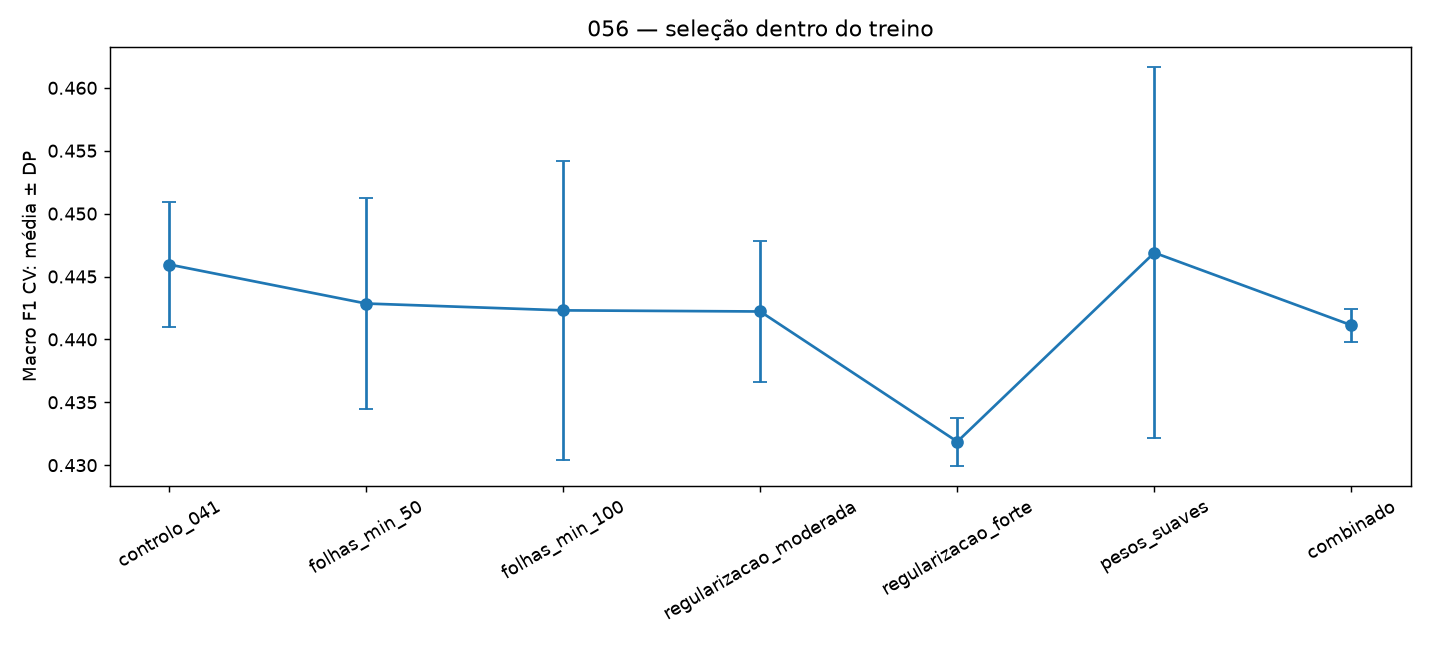

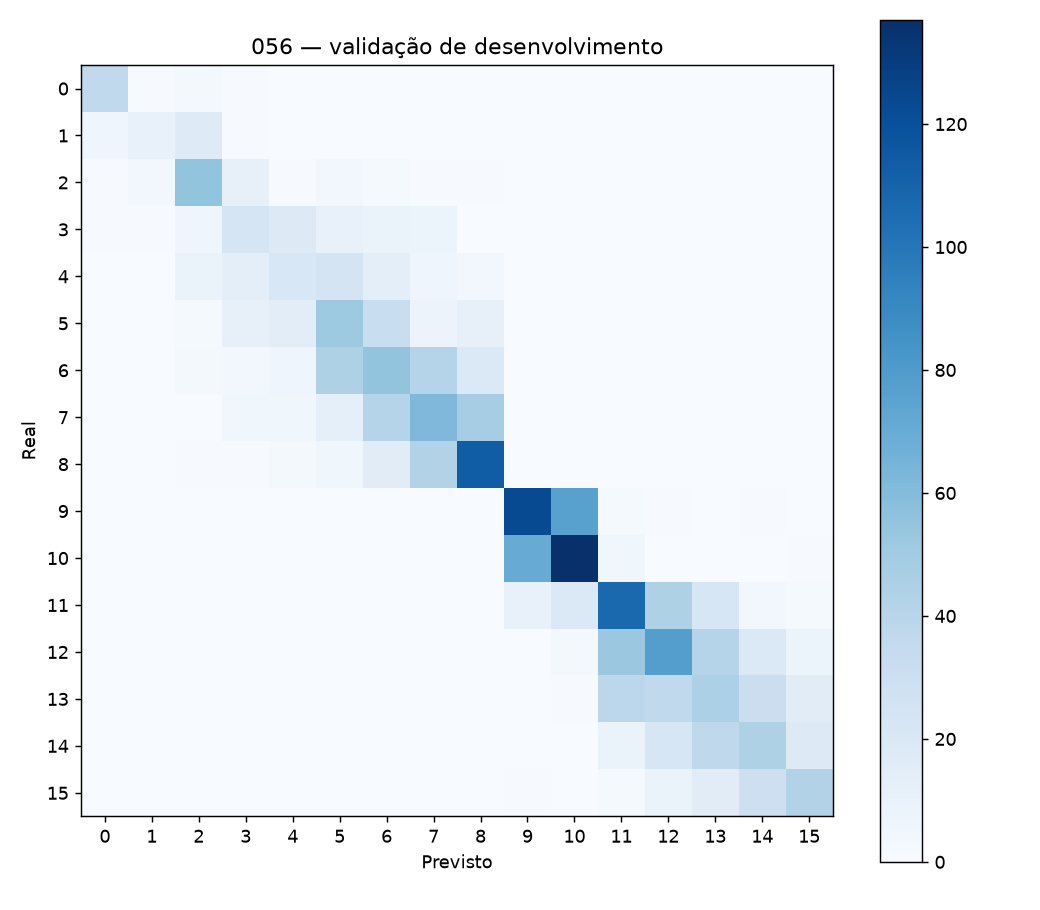

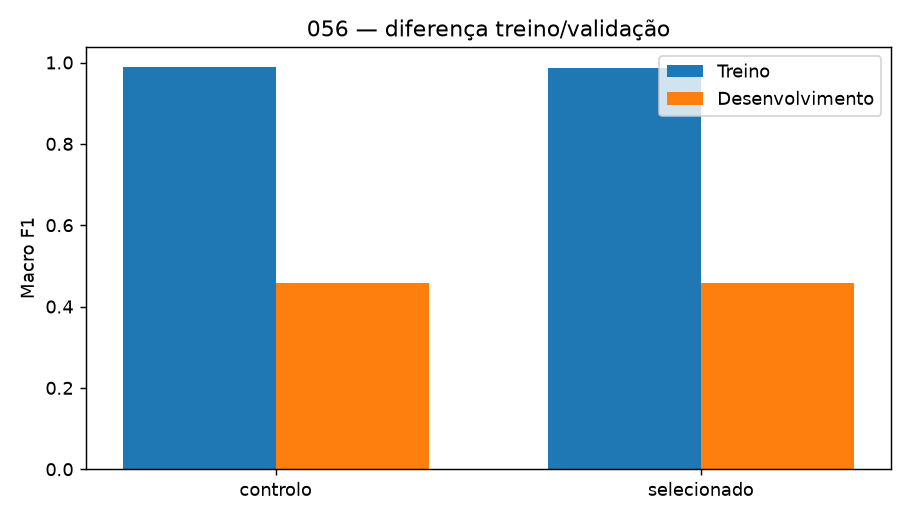

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/experiments_056_058.py').exists())
sys.path.insert(0, str(root))
from src.experiments_056_058 import run_experiment
result = run_experiment('056')
print('Protocolo:', result['protocol'])
print('Selecionado:', result['selected']['candidate'])
print('Versões:', result['context']['versions'])
print('Duração da corrida original (s), incluindo preparação e avaliação:', result['seconds'])
print('Diferenças emparelhadas CV:', result['paired_cv'])
display(pd.DataFrame([{'configuração':r['candidate']['label'], 'Macro F1 CV':r['mean'], 'DP':r['std'], 'folds':r['folds']} for r in result['candidates']]))
display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':m['macro_f1'],'accuracy':m['accuracy']} for name,groups in result['fixed'].items() for part,m in groups.items()]))
for name, groups in result['fixed'].items():
    print('Por escalão:', name)
    display(pd.DataFrame(groups['validation']['per_class']))
for p in sorted((root/'reports').glob('experiencia_056_*.png')):
    display(Image(filename=str(p)))
print('CSV:', result['submission'])
print('Kaggle:', result['kaggle_score'])


## Conclusões locais

- Macro F1: **0.4571**; accuracy: **0.4574**.
- Diferença face ao controlo contemporâneo: **-0.0017** no desenvolvimento.
- Seleção CV: `pesos_suaves`; diferença média emparelhada **+0.0009**.
- CSV: `submissions/submission_056_lightgbm_afinacao.csv`. Motivo se não gerado: [].
- A seleção foi interna. Uma margem pequena ou um CSV distinto não prova melhoria no Kaggle.
- Melhorias seguintes: analisar estabilidade nos folds e os escalões 1, 6 e 13 antes de aumentar a pesquisa.

## Registo Kaggle

- Data: 19/11
- Pontuação Kaggle: 0.46 
- Melhorias: variar o número de árvores e a taxa de aprendizagem, selecionando dentro do treino. Por agora, aguardar a mistura com LightGBM do 072.

